# Entangled-Polymer Viscoelastic Relaxation Spectrum

Recover continuous relaxation strength and a discrete Maxwell representation from measured storage and loss moduli of an entangled polymer blend over a finite oscillatory-shear frequency band.

This maintainer notebook actively reconstructs the complete bound observations with local numerical modules. It distinguishes the independently reproduced original method from fresh cleaned results. There is no cache-preview path. The paper describes the selected model; the exact bound dataset and modern port have separate provenance.

## Observation and inverse problem

Let omega be angular deformation frequency (rad/s), tau relaxation time (s), and h(tau)>=0 the modulus density per logarithmic relaxation time (Pa). The fluid generalized-Maxwell model is
```math
G'(\omega)=\int\frac{(\omega\tau)^2}{1+(\omega\tau)^2}h(\tau)d\ln\tau,
\qquad
G''(\omega)=\int\frac{\omega\tau}{1+(\omega\tau)^2}h(\tau)d\ln\tau.
```
G' and G'' are measured storage and loss moduli (Pa). The alternative discrete representation replaces each integral by a sum over positive mode strengths g[k] (Pa) at positive times tau[k] (s). This bound fluid model has zero equilibrium plateau modulus. Recover both representations from the complete 100-point author-curated experimental polyisoprene-blend spectrum. No relaxation spectrum is directly measured, and finite bandwidth poorly constrains very fast or slow modes.

## Implemented mathematics and numerical conventions

The selected method is the modern author implementation of Shanbhag's Bayesian nonlinear Tikhonov spectrum and AIC-selected discrete Maxwell modes. Preserve all 100 native observation pairs. Sort and deduplicate angular frequency, then linearly interpolate G',G'' on 100 geometrically spaced points between exact endpoints; no log-amplitude interpolation. Stack storage then loss, G in Pa. Relative weights are all one. No zero or negative observed modulus is allowed by the relative residual objective.

Continuous grid has ns=100, s_min=exp(-π/2)/omega_max and s_max=exp(π/2)/omega_min; s_j=s_min*(s_max/s_min)^(j/(ns-1)). Build logarithmic trapezoidal weights and stack the two Maxwell kernels from README into K. H_j=ln(h_j), h in Pa relative to the one-Pa numerical unit. The objective is sum_i (1-[K exp(H)]_i/G_i)²+lambda*sum_j (H_(j+2)-2H_(j+1)+H_j)². There are no hidden one-half or sample-count factors. The analytic data Jacobian is -K_ij exp(H_j)/G_i; penalty Jacobian is sqrt(lambda) times the second-difference matrix. scipy.optimize.least_squares uses its trust-region default and default ftol/xtol/gtol=1e-8. Initialize H=-5+sin(πs), run first with lambda=1. No plateau term is fitted in standard execution.

Bayesian scan: 26 logarithmically spaced candidate lambdas from 1e-10 to 1e3 (density=2 points per decade), traversed high to low with warm starts. Let A=D2ᵀD2, r=1-Kexp(H)/G, J=-Kdiag(exp H)/G, B=JᵀJ+diag(rᵀJ). Log evidence is -||r||²-lambda||D2H||² + (logabsdet(A)+ns ln(lambda)-logabsdet(lambda A+B))/2-lambda. Preserve the source's use of slogdet log-absolute values, including the rank-deficient curvature prior; it is a comparative empirical evidence convention, not a proper absolute posterior probability. Stop the lower-lambda tail when evidence falls more than 18 below the largest seen. Normalize exp(log evidence) and select exp(sum p ln(lambda)). Smoothness nudge is zero. Refit at selected lambda from the initial regularized H. Error band is spread of H across candidates with probability >0.1, or probability-weighted spread if none exceeds that mass.

Discrete spectrum: candidate count N_min=max(floor(0.5 log10(omega_max/omega_min)),2), N_max=min(floor(3 log10(span)),n/4), inclusive. Scan placement blend weights wb=0.2,0.4,0.6,0.8. Build a density from each continuous kernel contribution, normalize storage-channel contributions by predicted storage modulus (loss contributions remain unnormalized as in source), sum contributions, normalize over ln(s), and blend (1-wb)*density+wb*mean(density). Cubic interpolation and cumulative trapezoidal integration on 100 equally spaced ln(s) values distribute mode positions by equal probability. For each candidate solve nonnegative weighted relative least squares with nnls(maxiter=100000), prune g/max(g)<1e-7 and times outside [0.02/omega_max,50/omega_min]. Minimize AIC=2N+2*C_error*SSE with C_error=1/std(relative continuous residual). Recompute global best placement, refine each time by bounded least_squares with NNLS strengths at every evaluation, accepting a refinement only if it does not worsen residual. Sort by time. Merge closest adjacent modes if their ratio<1.25, at most three passes, minimizing integrated relative two-mode error with scipy.optimize.minimize and quad, followed by time refinement. Standard execution returns 13 retained modes for this bound dataset; the output shape is explicit.

Runtime source contains these local formulas and updates rather than importing the upstream package. Package configuration parsers, plotting and compatibility aliases were removed during extraction. Notebook comparisons actively recompute continuous and discrete fits, Bayesian evidence/AIC diagnostics, lambda factors 0.1/1/10 and reduced frequency acquisitions. The source's asymmetric mode-placement weighting and rank-deficient prior convention are preserved and disclosed, not presented as a newly corrected method. All required groups are evaluated independently; discrete strengths (Pa) and times (s) are never mixed in one error norm.

In [1]:
%matplotlib inline
from pathlib import Path
import os,sys,time,json,subprocess,hashlib
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
ROOT=next(p for p in [Path.cwd(),Path.cwd().parent] if (p/'src').is_dir())
os.chdir(ROOT)
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from src.preprocessing import load_data
from src.main import run
from src.visualization import make_figures,relative_error
data=load_data()
display(Markdown('| Observation | Internal shape | Dtype |\n| --- | --- | --- |\n'+'\n'.join(f'| {k} | {v.shape} | {v.dtype} |' for k,v in data.items())))

| Observation | Internal shape | Dtype |
| --- | --- | --- |
| angular_frequency | (100,) | float64 |
| storage_modulus | (100,) | float64 |
| loss_modulus | (100,) | float64 |

## Fresh full reconstruction

The standard local path below computes every required output quantity from the bound public measurements and writes the declared submission. Runtime includes the complete reconstruction. Evaluation is a separate subprocess using the standalone Judge.

In [2]:
start=time.perf_counter()
fresh=run()
solver_runtime_s=time.perf_counter()-start
judge_process=subprocess.run([sys.executable,'evaluation/judge.py','--prediction','output/reconstruction.npz','--report','output/judge_report.json'],capture_output=True,text=True,encoding='utf8',env=dict(os.environ,PYTHONIOENCODING='utf-8'))
assert judge_process.returncode==0,judge_process.stderr
judge_report=json.loads(Path('output/judge_report.json').read_text(encoding='utf8'))
assert judge_report['status']=='pass'
with np.load('evaluation/baseline_reference.npz',allow_pickle=False) as f:reference={k:f[k].copy() for k in f.files}
agreement={key:relative_error(fresh[key],reference[key]) for key in fresh}
print(json.dumps({'identity':'fresh cleaned full reconstruction','solver_runtime_s':solver_runtime_s,'upstream_relative_errors':agreement,'standalone_judge':judge_report},indent=2,allow_nan=False))

{
  "identity": "fresh cleaned full reconstruction",
  "solver_runtime_s": 0.4114274000748992,
  "upstream_relative_errors": {
    "reconstruction": 0.0,
    "maxwell_modes": 0.0,
    "fitted_moduli": 0.0
  },
  "standalone_judge": {
    "status": "pass",
    "passed": true,
    "metrics": {
      "reconstruction_relative_error": 0.0,
      "maxwell_modes_0_relative_error": 0.0,
      "maxwell_modes_1_relative_error": 0.0,
      "fitted_moduli_relative_error": 0.0
    },
    "thresholds": {
      "reconstruction_relative_error": {
        "comparison": "<=",
        "boundary": 1e-05
      },
      "maxwell_modes_0_relative_error": {
        "comparison": "<=",
        "boundary": 1e-05
      },
      "maxwell_modes_1_relative_error": {
        "comparison": "<=",
        "boundary": 1e-05
      },
      "fitted_moduli_relative_error": {
        "comparison": "<=",
        "boundary": 1e-05
      }
    },
    "errors": []
  }
}


## Scientific comparisons and recomputed experiments

The reconstruction figure includes measured signal consistency and independently reproduced upstream comparison. The robustness figure recomputes its model/regularization and acquisition/calibration changes. Original arrays are comparison inputs only; every curve labeled fresh is computed here. Exact numerical trace arrays are returned for the separately archived figure exports.

In [3]:
experiment_start=time.perf_counter()
figures,plot_trace,experiment_metrics=make_figures(data,fresh,reference)
plt.close('all')
experiment_runtime_s=time.perf_counter()-experiment_start
measurement={'identity':'fresh cleaned notebook reconstruction and actively recomputed comparisons','raw_data_sha256':hashlib.sha256(Path('data/raw_data.npz').read_bytes()).hexdigest(),'solver_runtime_s':solver_runtime_s,'experiments_runtime_s':experiment_runtime_s,'upstream_relative_errors':agreement,'scientific_measurements':experiment_metrics,'judge':judge_report,'historical_paper_numbers_used':False}
Path('notebooks/reference_outputs/fresh_measurements.json').write_text(json.dumps(measurement,indent=2,allow_nan=False)+'\n',encoding='utf8')
print(json.dumps(experiment_metrics,indent=2,allow_nan=False))

{
  "upstream_relative_error": 0.0,
  "continuous_relative_residual_norm": 0.314077459094319,
  "discrete_relative_residual_norm": 0.15646932770257801,
  "lambda_selected": 3.362042204095548,
  "discrete_mode_count": 13,
  "lambda_factor_mode_count_relative_residual": [
    [
      0.1,
      13,
      0.2174782613621821
    ],
    [
      1,
      13,
      0.314077459094319
    ],
    [
      10,
      13,
      0.633551283161425
    ]
  ]
}


### Reconstruction

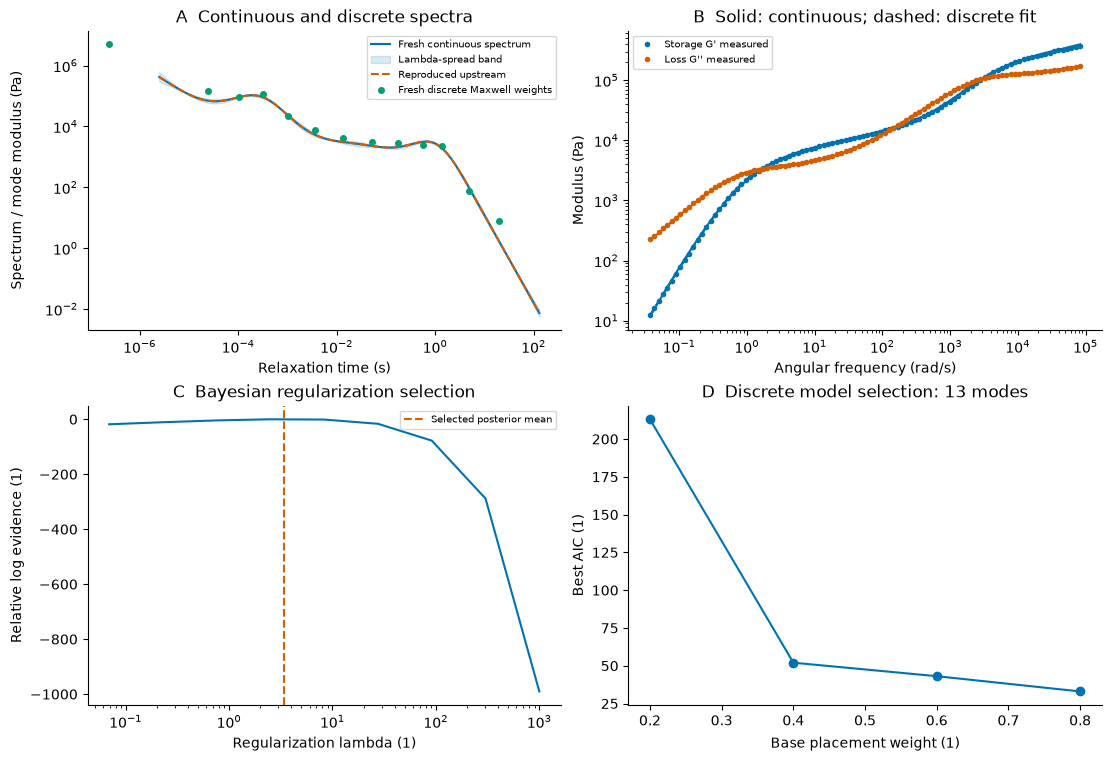

### Robustness

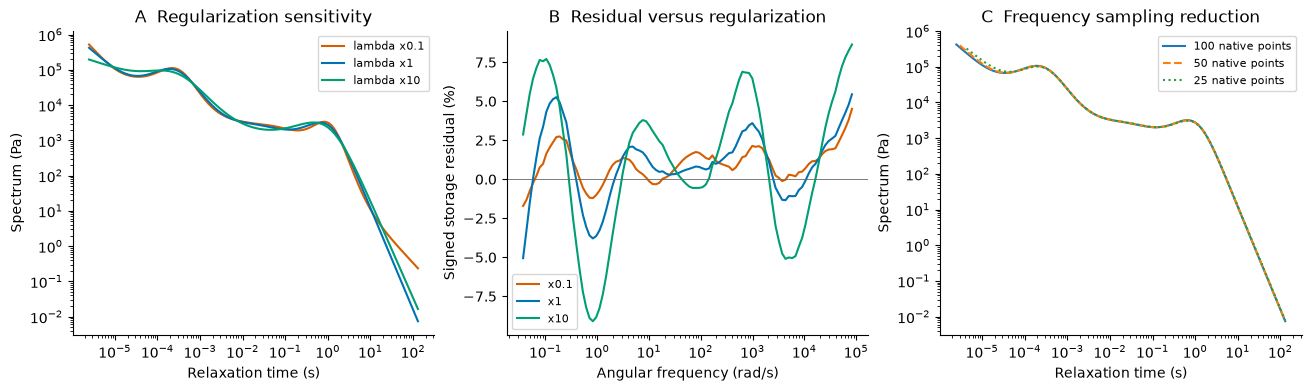

### Inverse Diagnostics

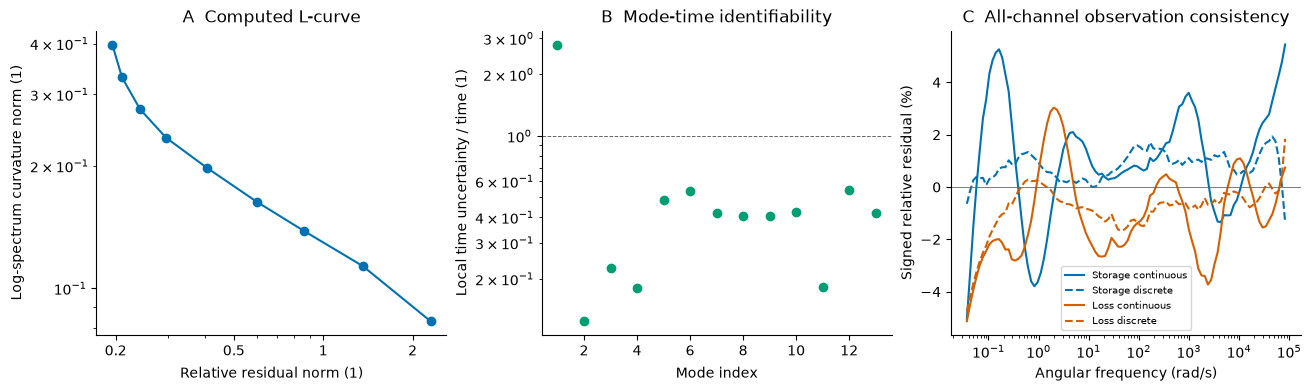

In [4]:
for figure_name,figure in figures.items():
    display(Markdown('### '+figure_name.replace('_',' ').title()))
    display(figure)
    plt.close(figure)

## Interpretation and limitations

The continuous and discrete spectra both describe the measured dynamic moduli; their strengths have Pa units but different integration measures. The selected 13-mode representation is reproducible, while other smoothing levels and sampling patterns yield different spectra. The evidence and AIC plots are actual computed diagnostics. The retained source evidence convention uses a numerically rank-deficient curvature prior and an asymmetric mode-placement weighting; interpret evidence comparatively, not as an absolute posterior probability. The Watanabe binary-blend data are experimental; the rejected symmetric-star candidate was not substituted or labeled as measurement.

Agreement with the standard method establishes implementation fidelity. Independent mathematical tests check operators and signs, while measured residuals and sensitivity studies bound physical interpretation. No reconstruction is relabeled as ground truth.

## Sources

Shanbhag, Relaxation spectra using nonlinear Tikhonov regularization with a Bayesian criterion, Rheologica Acta 59 (2020), 509–520. https://doi.org/10.1007/s00397-020-01212-w

Data: Watanabe et al., Test of full and partial tube dilation pictures in entangled blends of linear polyisoprenes, Macromolecules 37 (2004), 6619–6631. https://doi.org/10.1021/ma030443y. Method predecessor: Takeh and Shanbhag (2013), https://doi.org/10.3933/ApplRheol-23-24628.